## Importing Required Libraries

In [74]:
import numpy as np
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.models.word2vec import Text8Corpus
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

from gensim.test.utils import datapath
import pickle
import gzip
from sklearn.cluster import KMeans


## Load the Text8 Dataset
The **Text8 dataset** is a large-scale dataset extracted from Wikipedia, often used for training word embeddings.  
It consists of approximately 17 million words in a single text file, formatted as a sequence of words without punctuation.

In this step, you will:
1. **Download the Text8 dataset** using Gensim's downloader.
2. **Convert it to a list named text8_corpus** to use it for training.

In [39]:
# Downloading the Text8 dataset using Gensim's downloader
dataset_path = api.load("text8", return_path=True)

# Display the dataset path
print(f"Dataset downloaded to: {dataset_path}")

Dataset downloaded to: C:\Users\niush/gensim-data\text8\text8.gz


In [40]:
# Reading the dataset using Text8Corpus
text8_corpus = Text8Corpus(dataset_path)

# Converting the corpus to a list of sentences
text8_corpus = [list(sentence) for sentence in text8_corpus]

In [41]:
# Displaying a sample of the data
print(text8_corpus[:1])  # Displaying the first 3 sentences

len(text8_corpus)

[['anarchism', 'originated', 'as', 'a', 'term', 'of', 'abuse', 'first', 'used', 'against', 'early', 'working', 'class', 'radicals', 'including', 'the', 'diggers', 'of', 'the', 'english', 'revolution', 'and', 'the', 'sans', 'culottes', 'of', 'the', 'french', 'revolution', 'whilst', 'the', 'term', 'is', 'still', 'used', 'in', 'a', 'pejorative', 'way', 'to', 'describe', 'any', 'act', 'that', 'used', 'violent', 'means', 'to', 'destroy', 'the', 'organization', 'of', 'society', 'it', 'has', 'also', 'been', 'taken', 'up', 'as', 'a', 'positive', 'label', 'by', 'self', 'defined', 'anarchists', 'the', 'word', 'anarchism', 'is', 'derived', 'from', 'the', 'greek', 'without', 'archons', 'ruler', 'chief', 'king', 'anarchism', 'as', 'a', 'political', 'philosophy', 'is', 'the', 'belief', 'that', 'rulers', 'are', 'unnecessary', 'and', 'should', 'be', 'abolished', 'although', 'there', 'are', 'differing', 'interpretations', 'of', 'what', 'this', 'means', 'anarchism', 'also', 'refers', 'to', 'related', 's

1701

## Train a Word2Vec Model in CBOW Mode

In this step, you will initialize a Word2Vec model and train it using a specific architecture.  
The model will learn word representations based on a **context-predicting approach**, where surrounding words help predict the target word.  

Consider the impact of different parameters such as:
- The size of the word representations(e.g., 300 dimensions).
- The number of neighboring words considered(e.g., 5 neighbors).
- The minimum occurrences required for a word to be included in the vocabulary(e.g., 5 occurrences).
- The number of CPU cores used for training(e.g., 4 cores).

Run the code below to train the model for **one epoch**.


In [78]:
# Parameters
vector_size = 300   # Dimensionality of the word vectors
window_size = 5     # Number of context words to consider
min_word_count = 5  # Minimum word count threshold
num_workers = 4     # Number of CPU cores to use
epochs = 1          # Number of training epochs

# Initialize and train the Word2Vec model using CBOW (sg=0)
CBOW_model = Word2Vec(
    sentences=text8_corpus,
    vector_size=vector_size,
    window=window_size,
    min_count=min_word_count,
    workers=num_workers,
    sg=0  # 0 for CBOW
)

# Train the model for the specified number of epochs
CBOW_model.train(text8_corpus, total_examples=CBOW_model.corpus_count, epochs=epochs)

# Saving the model
CBOW_model.save("text8_word2vec_cbow.model")

print("Model training completed successfully!")


Model training completed successfully!


## Example Words
We select a few words of interest.

In [79]:
words = ["king", "queen", "man", "woman", "car", "bus"]

## Compare Word Similarities

After training the Word2Vec model, we can analyze how well it captures relationships between words.  
In this step, we:
- Find the **top 5 most similar words** for each based on cosine similarity.
- Display the results in a structured format.

Words with high similarity scores are expected to have similar meanings or occur in similar contexts.  
If a word is **not found in the vocabulary**, it means it didn’t meet the minimum occurrence threshold during training.


In [80]:

# Function to find and print the top 5 most similar words and save their vectors
def print_and_save_similar_words(model, words, dict_vect, file_name, top_n_words=5):

    for word in words:
        if word in model.wv:
            display(Markdown(f"**{word}:**"))

            dict_vect[word] = model.wv[word]

            # Find similar words (this is the main part)
            similar_words = model.wv.most_similar(word, topn=top_n_words)
            # print(type(similar_words))
            # print(len(similar_words))
            # print(similar_words)
            
            for similar_word, similarity_score in similar_words:
                display(Markdown(f"- {similar_word}: {similarity_score:.4f}"))
                # Save the similar word vectors to the dictionary
                if similar_word not in dict_vect:
                    dict_vect[similar_word] = model.wv[similar_word]
                    
        else:
            display(Markdown(f"**{word}** is not in the vocabulary."))
        
    # Save the word vectors to a file for future use
    with open(f"{file_name}.pkl", "wb") as file:
        pickle.dump(dict_vect, file)
    
    return dict_vect

In [81]:
# Load the trained model (if needed - in our case we do not need it)
# model = Word2Vec.load("text8_word2vec_cbow.model")

saved_word_vectors = {}

top_n_most_similar_words = 5
file_name_CBOW = "saved_word_vectors_CBOW"

# Call the function and get the saved vectors
word_vectors = print_and_save_similar_words(CBOW_model, words, saved_word_vectors, file_name_CBOW, top_n_most_similar_words)

**king:**

- kings: 0.6079

- prince: 0.6078

- queen: 0.5872

- throne: 0.5790

...

- tram: 0.7812

- buses: 0.7653

- commuter: 0.7178

- rail: 0.7166

- trains: 0.7149

## Visualizing Word Embeddings

Word embeddings are high-dimensional vectors, making them difficult to interpret directly.  
To visualize them, we use **Principal Component Analysis (PCA)** to reduce their dimensionality from 300 to 2.

### Steps:
1. Extract word vectors for selected words.
2. Apply **PCA** to reduce dimensionality from 300 to 2.
3. Plot the words in a 2D space.

Words that appear in similar contexts should be **closer together** in the plot.


In [82]:
print("type(word_vectors): ", type(word_vectors))

word_vectors_list_keys = np.array(list(word_vectors.keys()))

print("\nword_vectors_list_keys.shape: ", word_vectors_list_keys.shape)
print("word_vectors_list_keys: ", word_vectors_list_keys)
print("word_vectors_list_keys[0].shape: ", word_vectors_list_keys[0].shape)


word_vectors_list_values = np.array(list(word_vectors.values()))

print("\nword_vectors_list_values.shape: ", word_vectors_list_values.shape)
# print("word_vectors_list_values: ", word_vectors_list_values)
print("word_vectors_list_values[0].shape (Before PCA): ", word_vectors_list_values[0].shape)


type(word_vectors):  <class 'dict'>

word_vectors_list_keys.shape:  (30,)
word_vectors_list_keys:  ['king' 'kings' 'prince' 'queen' 'throne' 'pharaoh' 'elizabeth' 'princess'
 'victoria' 'man' 'woman' 'girl' 'gentleman' 'creature' 'person' 'child'
 'prostitute' 'herself' 'car' 'cars' 'driver' 'motorcycle' 'automobile'
 'taxi' 'bus' 'tram' 'buses' 'commuter' 'rail' 'trains']
word_vectors_list_keys[0].shape:  ()

word_vectors_list_values.shape:  (30, 300)
word_vectors_list_values[0].shape (Before PCA):  (300,)


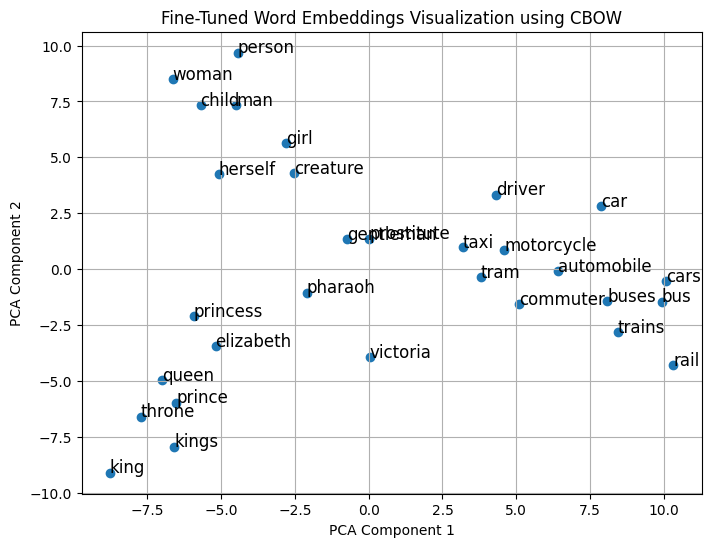

In [84]:
# Apply PCA to reduce dimensionality from 300 to 2
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(word_vectors_list_values) # Result

# Plotting the words in 2D space
plt.figure(figsize=(8, 6))
plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1])

# Annotate each point with the word
for i, word in enumerate(word_vectors_list_keys):
    plt.annotate(word, (reduced_vectors[i, 0], reduced_vectors[i, 1]), fontsize=12)

plt.title("Fine-Tuned Word Embeddings Visualization using CBOW")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True)
plt.show()


Applying a little clustering here :) - k-means

c:\Users\niush\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


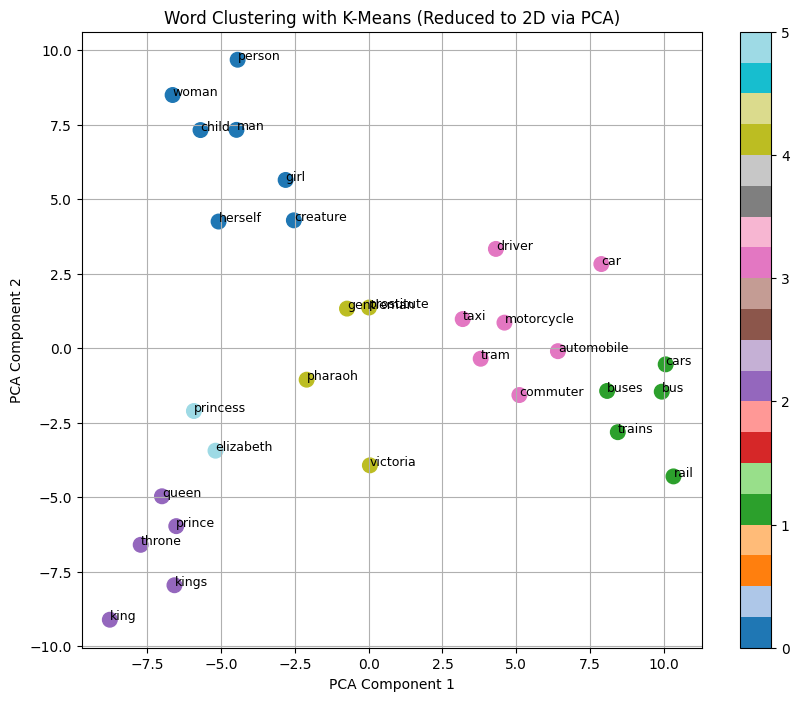

In [87]:
# Apply K-Means Clustering with higher number of clusters for better separation
num_clusters = len(word_vectors_list_keys) // 5  # Using half of the words as clusters
kmeans = KMeans(n_clusters=num_clusters, random_state=0)
labels = kmeans.fit_predict(reduced_vectors)

# Plotting the words in 2D space
plt.figure(figsize=(10, 8))
scatter = plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], c=labels, cmap='tab20', s=110)

# Annotate each point with the word
for i, word in enumerate(word_vectors_list_keys):
    plt.annotate(word, (reduced_vectors[i, 0], reduced_vectors[i, 1]), fontsize=9)

plt.title("Word Clustering with K-Means (Reduced to 2D via PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter)
plt.grid(True)
plt.show()

c:\Users\niush\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


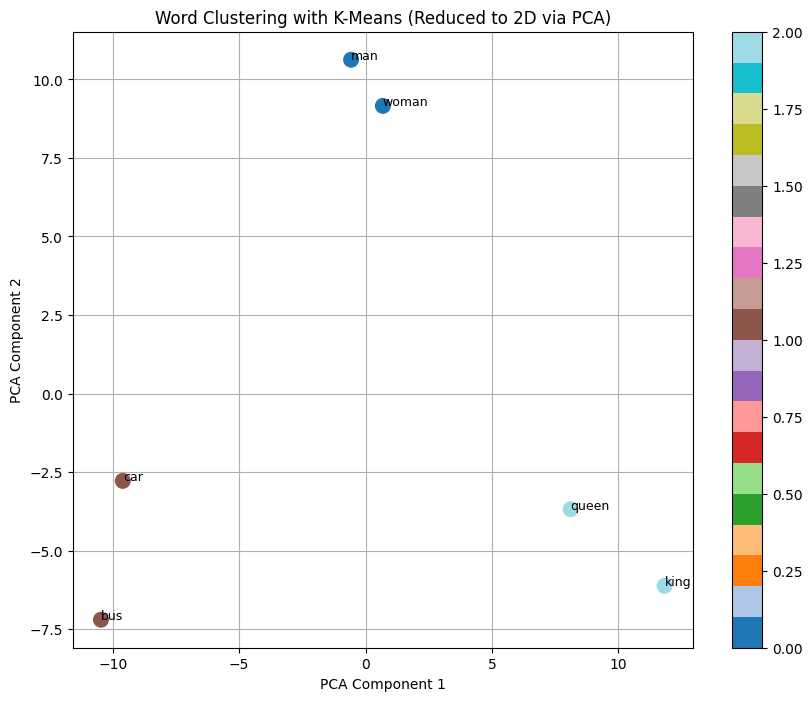

In [35]:
# Apply K-Means Clustering with higher number of clusters for better separation
num_clusters = len(word_vectors_list_keys) // 2  # Using half of the words as clusters
kmeans = KMeans(n_clusters=num_clusters, random_state=0)
labels = kmeans.fit_predict(reduced_vectors)

# Plotting the words in 2D space
plt.figure(figsize=(10, 8))
scatter = plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], c=labels, cmap='tab20', s=110)

# Annotate each point with the word
for i, word in enumerate(word_vectors_list_keys):
    plt.annotate(word, (reduced_vectors[i, 0], reduced_vectors[i, 1]), fontsize=9)

plt.title("Word Clustering with K-Means (Reduced to 2D via PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter)
plt.grid(True)
plt.show()

## Training Word2Vec with Skip-gram

Now, we will train another Word2Vec model using a different architecture called **Skip-gram**.  
Unlike the previous CBOW approach, Skip-gram learns to predict **context words** given a target word, making it more effective for learning representations of rare words.

Repeat the previous steps:
1. Initialize a new Word2Vec model with a different training mode.
2. Train it using the **Text8 dataset** for one epoch.


In [42]:
# Parameters
vector_size = 300   # Dimensionality of the word vectors
window_size = 5     # Number of context words to consider
min_word_count = 5  # Minimum word count threshold
num_workers = 4     # Number of CPU cores to use
epochs = 1          # Number of training epochs


# Initialize a new Word2Vec model using Skip-gram
skipgram_model = Word2Vec(
    sentences=text8_corpus,
    vector_size=vector_size,
    window=window_size,
    min_count=min_word_count,
    workers=num_workers,
    sg=1  # 1 for Skip-gram
)

# Train the model for one epoch
skipgram_model.train(text8_corpus, total_examples=skipgram_model.corpus_count, epochs=epochs)

# Save the trained Skip-gram model
skipgram_model.save("text8_word2vec_skipgram.model")

print("Skip-gram model training completed successfully!")


Skip-gram model training completed successfully!


## Compare Word Similarities (Skip-gram)
Now, we repeat the similarity comparison, but this time using the **Skip-gram** model.

- Skip-gram focuses on predicting surrounding words given a target word.
- It is better suited for smaller datasets and learns high-quality embeddings, especially for infrequent words.
- Here, we retrieve and display the most similar words for a given set of words.


In [88]:
# Using the last function that we wrote for this part

# Load the trained Skip-gram model (if needed - in our case we do not need it)
# skipgram_model = Word2Vec.load("text8_word2vec_skipgram.model")

saved_word_vectors = {}

top_n_most_similar_words = 5
file_name_skipgram = "saved_word_vectors_skipgram"

# Call the function and get the saved vectors
word_vectors = print_and_save_similar_words(skipgram_model, words, saved_word_vectors, file_name_skipgram, top_n_most_similar_words)

**king:**

- canute: 0.6150

- valdemar: 0.5994

- elessar: 0.5917

- wenceslaus: 0.5739

...

- buses: 0.7101

- tram: 0.6415

- minibus: 0.6237

- intercity: 0.6207

- cta: 0.6178

## Visualizing Word Embeddings (Skip-gram)
Now, we visualize the word embeddings obtained from the **Skip-gram** model.

In [89]:
print("type(word_vectors): ", type(word_vectors))

word_vectors_list_keys = np.array(list(word_vectors.keys()))

print("\nword_vectors_list_keys.shape: ", word_vectors_list_keys.shape)
print("word_vectors_list_keys: ", word_vectors_list_keys)
print("word_vectors_list_keys[0].shape: ", word_vectors_list_keys[0].shape)


word_vectors_list_values = np.array(list(word_vectors.values()))

print("\nword_vectors_list_values.shape: ", word_vectors_list_values.shape)
# print("word_vectors_list_values: ", word_vectors_list_values)
print("word_vectors_list_values[0].shape (Before PCA): ", word_vectors_list_values[0].shape)


type(word_vectors):  <class 'dict'>

word_vectors_list_keys.shape:  (34,)
word_vectors_list_keys:  ['king' 'canute' 'valdemar' 'elessar' 'wenceslaus' 'capet' 'queen'
 'elizabeth' 'margrethe' 'consort' 'isabella' 'hrh' 'man' 'woman' 'shaves'
 'gentleman' 'men' 'thyself' 'girl' 'prostitute' 'senex' 'widower' 'car'
 'cars' 'driver' 'racer' 'automobile' 'sauber' 'bus' 'buses' 'tram'
 'minibus' 'intercity' 'cta']
word_vectors_list_keys[0].shape:  ()

word_vectors_list_values.shape:  (34, 300)
word_vectors_list_values[0].shape (Before PCA):  (300,)


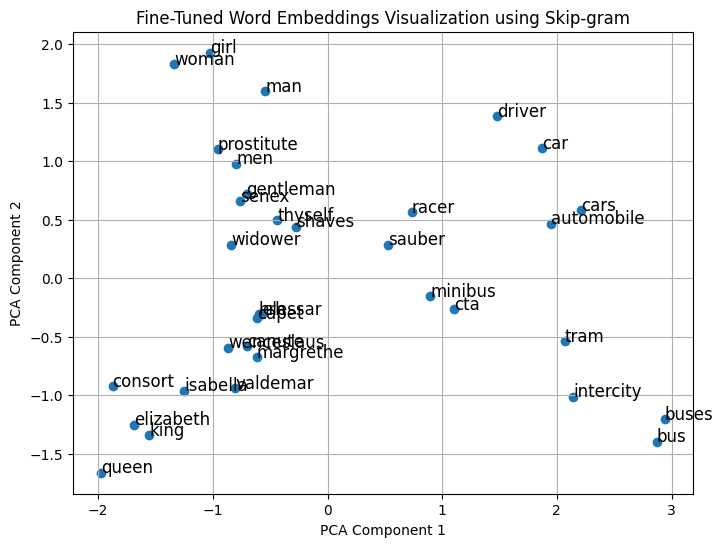

In [91]:
# Apply PCA to reduce dimensionality from 300 to 2
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(word_vectors_list_values) # Result

# Plotting the words in 2D space
plt.figure(figsize=(8, 6))
plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1])

# Annotate each point with the word
for i, word in enumerate(word_vectors_list_keys):
    plt.annotate(word, (reduced_vectors[i, 0], reduced_vectors[i, 1]), fontsize=12)

plt.title("Fine-Tuned Word Embeddings Visualization using Skip-gram")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True)
plt.show()


Applying a little clustering here :) - k-means

c:\Users\niush\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


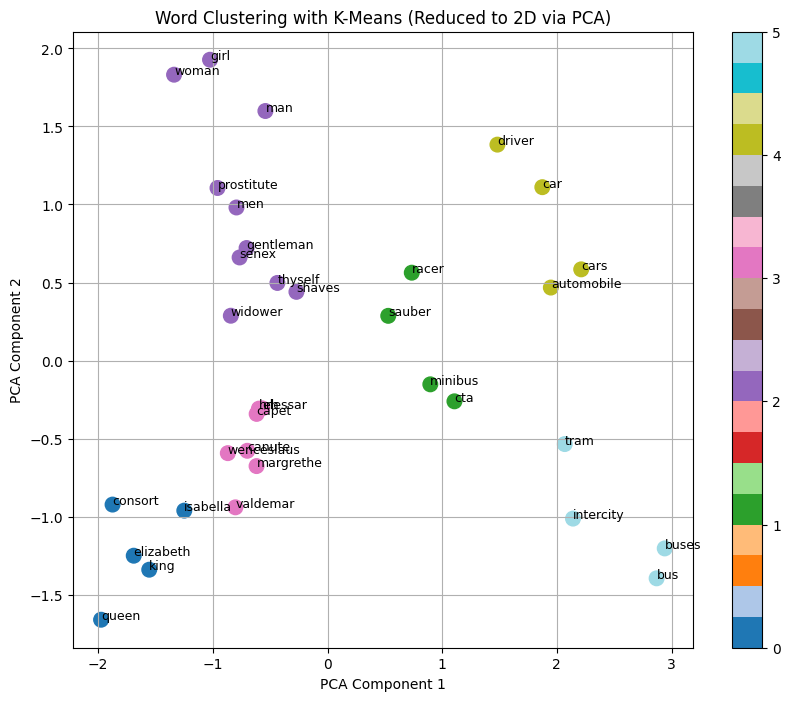

In [96]:
# Apply K-Means Clustering with higher number of clusters for better separation
num_clusters = len(word_vectors_list_keys) // 5  # Using half of the words as clusters
kmeans = KMeans(n_clusters=num_clusters, random_state=0)
labels = kmeans.fit_predict(reduced_vectors)

# Plotting the words in 2D space
plt.figure(figsize=(10, 8))
scatter = plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], c=labels, cmap='tab20', s=110)

# Annotate each point with the word
for i, word in enumerate(word_vectors_list_keys):
    plt.annotate(word, (reduced_vectors[i, 0], reduced_vectors[i, 1]), fontsize=9)

plt.title("Word Clustering with K-Means (Reduced to 2D via PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter)
plt.grid(True)
plt.show()

c:\Users\niush\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


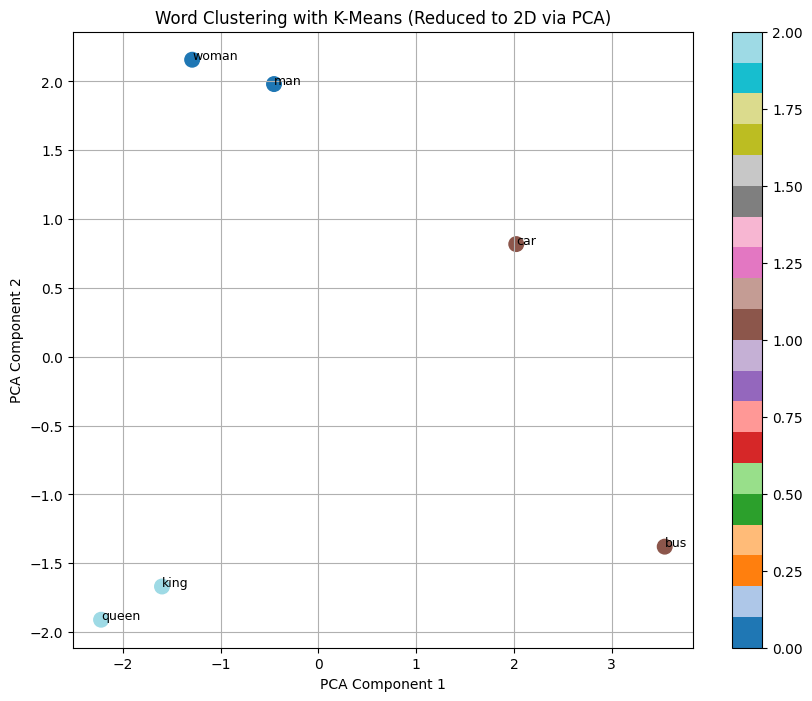

In [73]:
# Apply K-Means Clustering with higher number of clusters for better separation
num_clusters = len(word_vectors_list_keys) // 2  # Using half of the words as clusters
kmeans = KMeans(n_clusters=num_clusters, random_state=0)
labels = kmeans.fit_predict(reduced_vectors)

# Plotting the words in 2D space
plt.figure(figsize=(10, 8))
scatter = plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], c=labels, cmap='tab20', s=110)

# Annotate each point with the word
for i, word in enumerate(word_vectors_list_keys):
    plt.annotate(word, (reduced_vectors[i, 0], reduced_vectors[i, 1]), fontsize=9)

plt.title("Word Clustering with K-Means (Reduced to 2D via PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter)
plt.grid(True)
plt.show()